# ML Practical 1 – Principal Component Analysis (PCA)

**Aim:** Apply PCA to the Wine dataset to reduce 13 features to 2 components and visualize the classes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
url = "https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv"
df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
print(df.head())
print("\nDataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (178, 14)
   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065            

In [3]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Scaled Data:\n", X_scaled[:5])

Features Shape: (178, 13)
Target Shape: (178,)
Scaled Data:
 [[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
   1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 -2.49084714  0.01814502  0.56864766
   0.73362894 -0.82071924 -0.54472099 -0.29332133  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 -0.2687382   0.08835836  0.80899739
   1.21553297 -0.49840699  2.13596773  0.26901965  0.31830389  0.78858745
   1.39514818]
 [ 1.69154964 -0.34681064  0.4879264  -0.80925118  0.93091845  2.49144552
   1.46652465 -0.98187536  1.03215473  1.18606801 -0.42754369  1.18407144
   2.33457383]
 [ 0.29570023  0.22769377  1.84040254  0.45194578  1.28198515  0.80899739
   0.66335127  0.22679555  0.40140444 -0.31927553  0.36217728  0.44960118
  -0.03787401]]


In [4]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X.shape)
print("PCA Shape:", X_pca.shape)
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Explained:", pca.explained_variance_ratio_.sum())

Original Shape: (178, 13)
PCA Shape: (178, 2)
Explained Variance Ratio: [0.36198848 0.1920749 ]
Total Variance Explained: 0.5540633835693527


In [5]:
pca_df = pd.DataFrame(X_pca, columns=["Principal Component 1", "Principal Component 2"])
pca_df["Target"] = y.values
print(pca_df.head())

   Principal Component 1  Principal Component 2  Target
0               3.316751               1.443463       1
1               2.209465              -0.333393       1
2               2.516740               1.031151       1
3               3.757066               2.756372       1
4               1.008908               0.869831       1


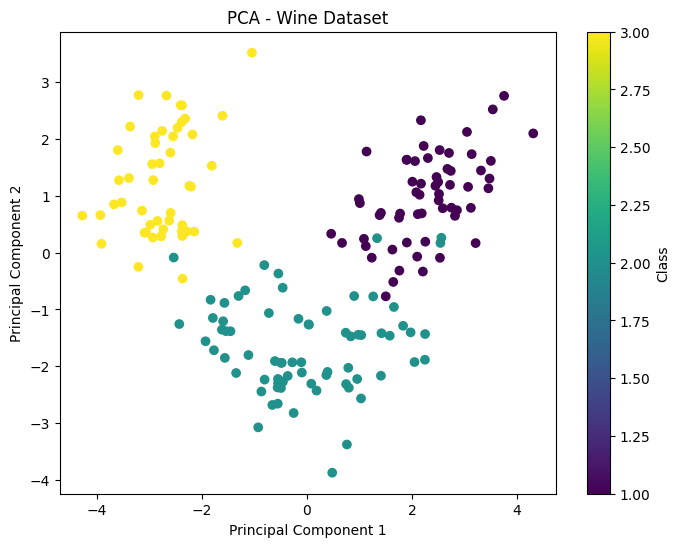

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Dataset")
plt.colorbar(label="Class")
plt.show()

# AIM: PCA reduces features while preserving maximum variance.
# PCA = Principal Component Analysis (Unsupervised Learning).

# LIBRARIES:
# numpy(np) = numerical operations
# pandas(pd) = dataset handling
# matplotlib(plt) = plotting graphs
# StandardScaler = standardizes data
# PCA = dimensionality reduction

# DATASET:
# pd.read_csv(url) = loads CSV into DataFrame
# df.shape = (rows, columns)
# df.head() = first 5 rows; head(n) = first n rows
# df.info() = column names, types, non-null counts
# df.isnull().sum() = missing values per column

# FEATURES & TARGET:
# df.iloc[:, :-1] = X (all rows, all columns except last)
# df.iloc[:, -1] = y (all rows, last column)
# : = all rows; :-1 = except last column; -1 = last column

# SCALING:
# StandardScaler() = creates scaler
# fit() = learns mean & standard deviation
# transform() = applies scaling
# fit_transform(X) = fits + transforms X
# Formula: z = (x - mean) / standard deviation
# Result: mean ≈ 0, standard deviation ≈ 1

# PCA:
# PCA(n_components=2) = reduces features to 2 components
# pca.fit_transform(X_scaled) = learns PCA & reduces dimensions
# PC1 = maximum variance; PC2 = next maximum variance
# PCA reduces columns, NOT rows.
# explained_variance_ratio_ = variance retained by each PC
# .sum() = total variance retained by selected PCs

# DATAFRAME:
# pd.DataFrame(X_pca, columns=[...]) = creates new table
# y.values = target values as array
# pca_df["Target"] = adds target column

# PLOTTING:
# plt.figure(figsize=(8,6)) = graph size in inches
# plt.scatter(X_pca[:,0], X_pca[:,1], c=y)
# [:,0] = PC1 (X-axis); [:,1] = PC2 (Y-axis)
# c=y = colors dots according to class
# plt.xlabel() = X-axis label
# plt.ylabel() = Y-axis label
# plt.title() = graph title
# plt.colorbar(label="Class") = color legend/scale
# plt.show() = displays graph
# Each dot = one wine sample

# VIVA:
# PCA = unsupervised dimensionality reduction technique.
# WHY PCA? Reduce complexity, preserve variance, visualize data.
# WHY SCALING? Prevent large-scale features dominating PCA.
# WHAT IS VARIANCE? Spread of data around its mean.
# WHAT IS A FEATURE? Input column (X).
# WHAT IS TARGET? Output/class column (y).
# WHY 2 COMPONENTS? To visualize data in 2D.
# fit vs transform? Learn parameters vs apply transformation.
# PCA creates new features; it doesn't simply select old ones.

# FLOW:
# LOAD -> INSPECT -> SPLIT -> SCALE -> PCA -> PLOTs captured enough chemical differences to cleanly tell the three wine types apart!